# EDA of data sample


In [1]:
%matplotlib inline

In [ ]:
import data_profiling
import matplotlib.pyplot as plt
import pandas as pd

import wandb

## Create run instance from Wandb


In [3]:
run = wandb.init(project="nyc_airbnb", group="eda", save_code=True)
local_path = wandb.use_artifact("sample.csv:latest").file()
df = pd.read_csv(local_path)

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/ubuntu/.netrc.
wandb: Currently logged in as: pbojemski (pbojemski-none) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: WARNING Artifact "source-nyc_airbnb-_home_ubuntu_repo_build-ml-pipeline-for-short-term-rental-prices_EDA.ipynb" already exists with the same content. No new version will be created.


Profile data

Inspect all data we have


In [4]:
profile = data_profiling.ProfileReport(df)
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:00<00:00, 21.30it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Finding price outlier


In [5]:
df["price"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
1%          30.000000
5%          40.000000
10%         49.000000
25%         69.000000
50%        106.000000
75%        175.000000
90%        269.000000
95%        355.000000
99%        799.000000
99.5%     1000.000000
99.9%     3000.000000
max      10000.000000
Name: price, dtype: float64

In [ ]:
boundary = df["price"].quantile(0.95)
sorted_prices = df["price"].sort_values()
idx = sorted_prices.searchsorted(boundary)
surrounding = sorted_prices.iloc[idx - 200 :]
surrounding.value_counts().sort_index()

price
350      195
352        4
353        1
355       10
356        2
        ... 
7703       1
8000       1
8500       1
9999       3
10000      3
Name: count, Length: 337, dtype: int64

Check 350 as candidate for upper boundary as it seems higher values to be marginal in counts


In [ ]:
total = len(df)
above = (df["price"] > 350).sum()
at_boundary = (df["price"] == 350).sum()

print(f"Total records: {total}")
print(f"Records at 350: {at_boundary}")
print(f"Records above 350: {above}")
print(f"Percentage removed: {above / total * 100:.3f}%")

Total records: 48895
Records at 350: 381
Records above 350: 2456
Percentage removed: 5.023%


Check nearby thresholds to determine if proposed boundary is natural cutoff or not


In [8]:
for limit in [300, 350, 355, 375, 400, 500]:
    kept = (df["price"] <= limit).sum()
    removed = total - kept

    print(
        f"Max {limit}: "
        f"kept={kept} ({kept / total * 100:.2f}%), "
        f"removed={removed} ({removed / total * 100:.2f}%)"
    )

Max 300: kept=45538 (93.13%), removed=3357 (6.87%)
Max 350: kept=46439 (94.98%), removed=2456 (5.02%)
Max 355: kept=46454 (95.01%), removed=2441 (4.99%)
Max 375: kept=46632 (95.37%), removed=2263 (4.63%)
Max 400: kept=47132 (96.39%), removed=1763 (3.61%)
Max 500: kept=47851 (97.86%), removed=1044 (2.14%)


Distribution above 350


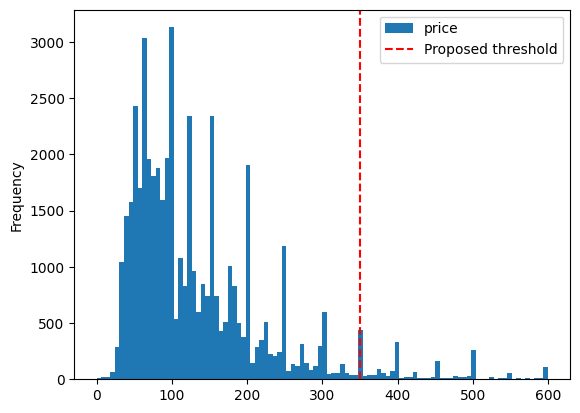

In [9]:
df["price"].plot.hist(bins=100, range=(0, 600))

plt.axvline(350, color="red", linestyle="--", label="Proposed threshold")

plt.legend()
plt.show()

Second minimum for price is 10 so let's keep it as minimum as price of 0 are of no interest to us as seen in profiling page.

95th quantile is 355 but, as proven above, values over 350 show significant distribution drop, so we can keep 350 as upper boundary and clean other data


In [ ]:
min_price = 10
max_price = 350
idx = df["price"].between(min_price, max_price)
df = df[idx].copy()

Make sure `last_review` is `datetime` type for easier datetime operations and accessing


In [11]:
df["last_review"] = pd.to_datetime(df["last_review"])

Run profiling again after price clean-up


In [30]:
profile = data_profiling.ProfileReport(df)
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:00<00:00, 19.54it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [14]:
df["price"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

count    46428.000000
mean       122.538016
std         71.862581
min         10.000000
1%          30.000000
5%          40.000000
10%         48.000000
25%         65.000000
50%        100.000000
75%        160.000000
90%        225.000000
95%        275.000000
99%        342.730000
99.5%      350.000000
99.9%      350.000000
max        350.000000
Name: price, dtype: float64

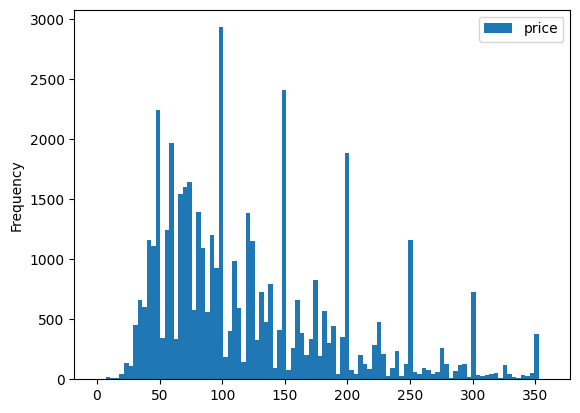

In [18]:
df["price"].plot.hist(bins=100, range=(0, 360))

plt.legend()
plt.show()

Investigate skewed `minimum_nights`

In [33]:
df["minimum_nights"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

count    46428.000000
mean         6.943181
std         19.877510
min          1.000000
1%           1.000000
5%           1.000000
10%          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
90%         28.000000
95%         30.000000
99%         43.730000
99.5%       90.000000
99.9%      300.000000
max       1250.000000
Name: minimum_nights, dtype: float64

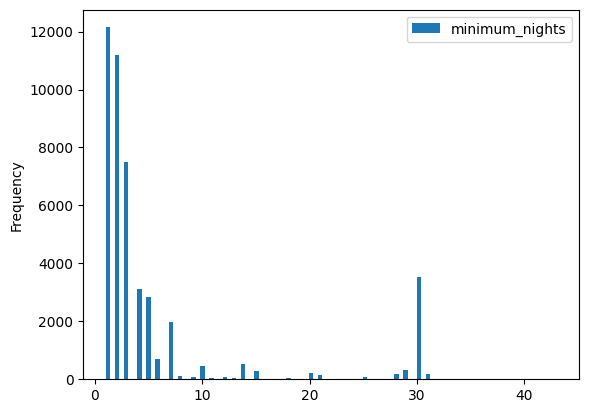

In [36]:
df["minimum_nights"].plot.hist(bins=100, range=(1, 43))

plt.legend()
plt.show()

Seems like `minimum_nights` extreme values are in minority of records and should not really affect rest of data

Additional observations:
- `last_review` - missing value is possible when there is no review at all and is later handled in `src/train_random_forest/run.py`
- `last_review`, `number_of_reviews` and `reviews_per_month` are exact same, showing lack of thereof in 19.8% of data - seems completely normal given the circumstances


In [12]:
run.finish()